# Comparación de tres modelos de IA para análisis de sentimientos (PLN)

**Caso de uso:** procesamiento de lenguaje natural (PLN) para clasificar opiniones escritas como positivas o negativas.

**Objetivo:** comparar tres modelos preentrenados de Hugging Face mediante accuracy, precision, recall, F1-score y latencia de inferencia.

**Modelos incluidos**
1. `distilbert/distilbert-base-uncased-finetuned-sst-2-english`
2. `textattack/bert-base-uncased-SST-2`
3. `siebert/sentiment-roberta-large-english`


## 1. Configuración del entorno y GPU

In [1]:
import os, sys, time, random, warnings
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)

import torch
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    DEVICE = 0
else:
    print("Se usará CPU. En Colab puedes activar GPU en Entorno de ejecución > Cambiar tipo de entorno de ejecución.")
    DEVICE = -1

Python: 3.13.15
PyTorch: 2.11.0+cu130
CUDA disponible: True
GPU: Tesla T4


## 2. Instalación de dependencias

In [2]:
%pip install -q "pandas==2.2.3" "pyarrow>=19,<24" transformers datasets accelerate scikit-learn matplotlib huggingface_hub

## 3. Autenticación en Hugging Face Hub

Los modelos y el dataset utilizados son públicos, por lo que el acceso  funciona sin token.

In [3]:
from huggingface_hub import login
from getpass import getpass

HF_TOKEN = os.environ.get("HF_TOKEN", "").strip()
if not HF_TOKEN:
    respuesta = input("¿Deseas autenticarte en Hugging Face? Escribe s para sí o n para continuar sin token: ").strip().lower()
    if respuesta == "s":
        HF_TOKEN = getpass("Pega tu token de Hugging Face (entrada oculta): ").strip()

if HF_TOKEN:
    login(token=HF_TOKEN, add_to_git_credential=False)
    print("Autenticación completada.")
else:
    print("Se continúa sin autenticación; los recursos de este notebook son públicos.")

¿Deseas autenticarte en Hugging Face? Escribe s para sí o n para continuar sin token: n
Se continúa sin autenticación; los recursos de este notebook son públicos.


## 4. Carga del dataset

Se utiliza IMDb, un conjunto de reseñas de películas etiquetadas como negativas (0) o positivas (1). Para una ejecución inicial se toma una muestra equilibrada del conjunto de prueba.

In [6]:

from datasets import load_dataset
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report
)

# Cargar el dataset IMDb usando su identificador completo
dataset = load_dataset("stanfordnlp/imdb", split="test")
df = dataset.to_pandas()[["text", "label"]]

# Muestra equilibrada por clase
N_PER_CLASS = 100

parts = []
for label in [0, 1]:
    class_df = df[df["label"] == label]

    part = class_df.sample(
        n=min(N_PER_CLASS, len(class_df)),
        random_state=SEED
    )
    parts.append(part)

eval_df = (
    pd.concat(parts)
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)

eval_df["label"] = eval_df["label"].astype(int)

print("Dataset cargado correctamente")
print("Total de ejemplos:", len(eval_df))
print(
    eval_df["label"]
    .value_counts()
    .rename(index={0: "negativa", 1: "positiva"})
)

display(eval_df.head(3))

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Dataset cargado correctamente
Total de ejemplos: 200
label
negativa    100
positiva    100
Name: count, dtype: int64


,text,label
0,"""Tenchi Muyo In Love 2"" is the third Tenchi mo...",0
1,The idea that anyone could of concocted such a...,0
2,He seems to be a control freak. I have heard h...,0


## 5. Definición de modelos y pipeline de inferencia

Se ejecuta un pipeline de clasificación de texto para cada modelo

In [7]:
from transformers import pipeline
from time import perf_counter

MODEL_IDS = [
    "distilbert/distilbert-base-uncased-finetuned-sst-2-english",
    "textattack/bert-base-uncased-SST-2",
    "siebert/sentiment-roberta-large-english",
]

texts = eval_df["text"].astype(str).tolist()
y_true = eval_df["label"].tolist()

def normalize_prediction(label):
    """Convierte etiquetas comunes de modelos SST-2 a 0=negativo y 1=positivo."""
    label = str(label).strip().upper()
    if label in {"POSITIVE", "LABEL_1", "POS", "1"} or "POSITIVE" in label:
        return 1
    if label in {"NEGATIVE", "LABEL_0", "NEG", "0"} or "NEGATIVE" in label:
        return 0
    raise ValueError(f"No se reconoce la etiqueta del modelo: {label}")

def evaluate_model(model_id, texts, y_true, batch_size=16):
    print(f"\nCargando: {model_id}")
    clf = pipeline(
        task="sentiment-analysis",
        model=model_id,
        device=DEVICE
    )
    start = perf_counter()
    outputs = clf(texts, batch_size=batch_size, truncation=True, max_length=512)
    elapsed = perf_counter() - start

    y_pred = [normalize_prediction(o["label"]) for o in outputs]
    metrics = {
        "modelo": model_id,
        "n_muestras": len(y_true),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1_score": f1_score(y_true, y_pred, zero_division=0),
        "latencia_total_s": elapsed,
        "latencia_media_ms": (elapsed / max(len(texts), 1)) * 1000,
        "muestras_por_segundo": len(texts) / max(elapsed, 1e-9),
    }
    del clf
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return metrics, y_pred, outputs

## 6. Evaluación de los tres modelos

In [8]:
results = []
predictions = {}
raw_outputs = {}

for model_id in MODEL_IDS:
    try:
        metrics, y_pred, outputs = evaluate_model(model_id, texts, y_true)
        results.append(metrics)
        predictions[model_id] = y_pred
        raw_outputs[model_id] = outputs
        print(classification_report(
            y_true, y_pred,
            labels=[0, 1],
            target_names=["negativa", "positiva"],
            zero_division=0
        ))
    except Exception as e:
        print(f"No se pudo evaluar {model_id}: {type(e).__name__}: {e}")
        print("Revisa conexión, memoria disponible y que el nombre del modelo siga vigente.")

results_df = pd.DataFrame(results)
if not results_df.empty:
    display(results_df.sort_values("f1_score", ascending=False).reset_index(drop=True).round(4))
else:
    print("No se obtuvo ningún resultado. Revisa los errores anteriores.")


Cargando: distilbert/distilbert-base-uncased-finetuned-sst-2-english


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

              precision    recall  f1-score   support

    negativa       0.95      0.96      0.96       100
    positiva       0.96      0.95      0.95       100

    accuracy                           0.95       200
   macro avg       0.96      0.95      0.95       200
weighted avg       0.96      0.95      0.95       200



,modelo,n_muestras,accuracy,precision,recall,f1_score,latencia_total_s,latencia_media_ms,muestras_por_segundo
0,siebert/sentiment-roberta-large-english,200,0.955,0.9596,0.95,0.9548,18.1594,90.7971,11.0136
1,textattack/bert-base-uncased-SST-2,200,0.915,0.9109,0.92,0.9154,6.2443,31.2214,32.0293
2,distilbert/distilbert-base-uncased-finetuned-s...,200,0.900,0.9348,0.86,0.8958,4.2293,21.1467,47.2886


## 7. Tabla comparativa y visualización

,modelo,accuracy,precision,recall,f1_score,latencia_total_s,latencia_media_ms,muestras_por_segundo
2,siebert/sentiment-roberta-large-english,0.955,0.9596,0.95,0.9548,18.1594,90.7971,11.0136
1,textattack/bert-base-uncased-SST-2,0.915,0.9109,0.92,0.9154,6.2443,31.2214,32.0293
0,distilbert/distilbert-base-uncased-finetuned-s...,0.900,0.9348,0.86,0.8958,4.2293,21.1467,47.2886


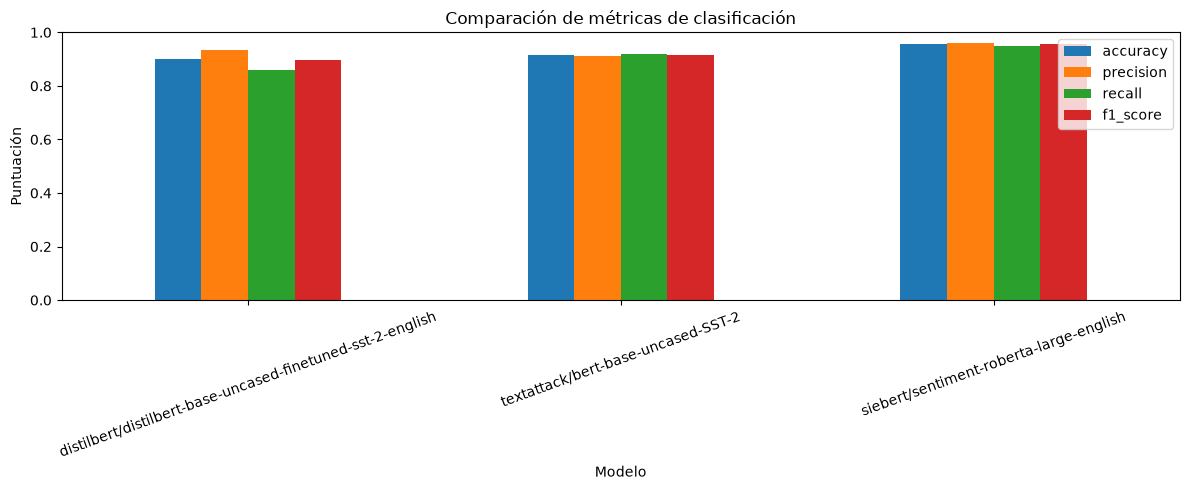

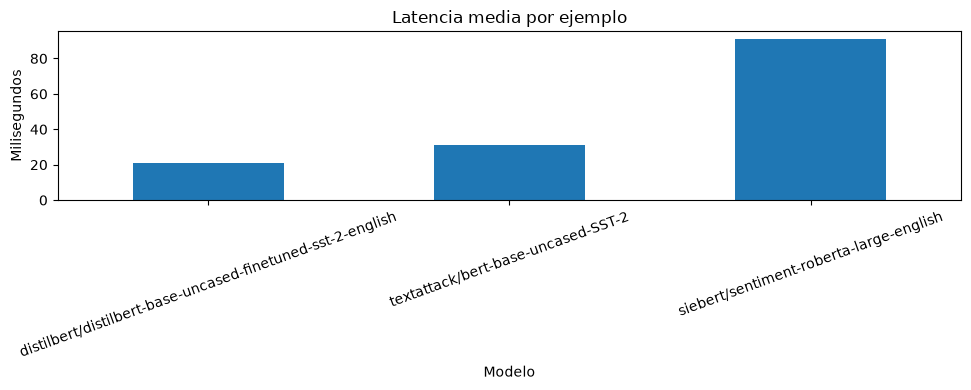

In [9]:
if not results_df.empty:
    metric_cols = ["modelo", "accuracy", "precision", "recall", "f1_score",
                   "latencia_total_s", "latencia_media_ms", "muestras_por_segundo"]
    display(results_df[metric_cols].sort_values("f1_score", ascending=False).round(4))

    import matplotlib.pyplot as plt
    plot_df = results_df.set_index("modelo")[["accuracy", "precision", "recall", "f1_score"]]
    ax = plot_df.plot(kind="bar", figsize=(12, 5), ylim=(0, 1), rot=20)
    ax.set_title("Comparación de métricas de clasificación")
    ax.set_ylabel("Puntuación")
    ax.set_xlabel("Modelo")
    plt.tight_layout()
    plt.show()

    ax = results_df.set_index("modelo")["latencia_media_ms"].plot(kind="bar", figsize=(10, 4), rot=20)
    ax.set_title("Latencia media por ejemplo")
    ax.set_ylabel("Milisegundos")
    ax.set_xlabel("Modelo")
    plt.tight_layout()
    plt.show()

## 8. Inspección de errores

In [10]:
if predictions:
    best_model = results_df.sort_values("f1_score", ascending=False).iloc[0]["modelo"]
    inspect_df = eval_df[["text", "label"]].copy()
    inspect_df["prediccion"] = predictions[best_model]
    inspect_df["resultado"] = inspect_df.apply(
        lambda r: "correcto" if r["label"] == r["prediccion"] else "error",
        axis=1
    )
    print("Modelo seleccionado por F1:", best_model)
    display(inspect_df[inspect_df["resultado"] == "error"].head(10))
else:
    print("No hay predicciones para inspeccionar.")

Modelo seleccionado por F1: siebert/sentiment-roberta-large-english


,text,label,prediccion,resultado
11,The main reason to check this one out is to wa...,1,0,error
26,FREDDY FORSYTH has come up with a storyline wh...,0,1,error
27,"As embarrassing as it is to admit, I was liste...",0,1,error
79,This the the final feature film that Michelang...,1,0,error
83,This movie was the second movie I saw on the c...,1,0,error
92,Ex-reporter Jacob Asch (Eric Roberts) is hired...,1,0,error
93,Rocketship X-M should be viewed by any serious...,0,1,error
184,I was really looking forward to watching this ...,1,0,error
194,A Cryptozoologist captures a mythical chupacab...,0,1,error


## 9. Conclusiones parciales

In [12]:
if not results_df.empty:
    best_f1 = results_df.loc[results_df["f1_score"].idxmax()]
    fastest = results_df.loc[results_df["latencia_media_ms"].idxmin()]
    print(f"Mejor F1-score en esta muestra: {best_f1['modelo']} ({best_f1['f1_score']:.3f}).")
    print(f"Menor latencia media: {fastest['modelo']} ({fastest['latencia_media_ms']:.2f} ms por ejemplo).")
    print("\nInterpretación:")
    print("- Accuracy resume la proporción total de predicciones correctas.")
    print("- Precision indica qué proporción de las reseñas predichas como positivas realmente lo son.")
    print("- Recall mide qué proporción de las reseñas positivas fue identificada.")
    print("- F1-score equilibra precision y recall.")
    print("- La latencia depende de la GPU/CPU, el tamaño de lote, la longitud de los textos y la carga del entorno.")
else:
    print("No hay métricas disponibles; no es posible generar conclusiones automáticas.")

Mejor F1-score en esta muestra: siebert/sentiment-roberta-large-english (0.955).
Menor latencia media: distilbert/distilbert-base-uncased-finetuned-sst-2-english (21.15 ms por ejemplo).

Interpretación:
- Accuracy resume la proporción total de predicciones correctas.
- Precision indica qué proporción de las reseñas predichas como positivas realmente lo son.
- Recall mide qué proporción de las reseñas positivas fue identificada.
- F1-score equilibra precision y recall.
- La latencia depende de la GPU/CPU, el tamaño de lote, la longitud de los textos y la carga del entorno.


### Conclusión general

La comparación permite observar que no basta con seleccionar el modelo que obtiene mayor accuracy: también es importante revisar precision, recall, F1-score y tiempo de respuesta. Para un uso real, los resultados deben validarse con textos del dominio donde se aplicará el sistema